# AirSense-R: Do Air-Quality Forecasters Keep Their Rank Under Sensor Degradation and Site Shift?

## 05 P6 sensor degradation

**Permitted partitions:** preflight uses TRAIN + VALIDATION only to reproduce original preprocessing and frozen predictions, then FINAL TEST — READ ONLY to replay accepted clean predictions. Evaluation uses the final test with predefined synthetic observation stresses. No model fitting, tuning or selection occurs.

Run preflight first in a fresh CPU runtime with your original model directory and AIRSENSE_GITHUB_TOKEN secret. The full evaluation covers 15 conditions, 63 realizations, and primary/no-forward-fill policies; allow hours for inference and bootstrap. Predictions persist in Drive with GitHub checksum references and compact results. No raw dataset is retained. Use one session only. See `docs/P6_WORKFLOW.md`.

## 1. Bootstrap
Use the code SHA from the same GitHub revision as this notebook. Installing the declared environment can require a kernel restart; preserve the checkout and rerun setup.

In [1]:
from pathlib import Path
import os, subprocess, sys

REPOSITORY = "https://github.com/Engr-Daniel/airsense-r.git"
# Use the full commit SHA of the GitHub revision containing this notebook.
# Resume using the SAME revision and run ID as the original execution.
TEST_MODE = os.environ.get("AIRSENSE_NOTEBOOK_TEST_MODE") == "1"
if TEST_MODE:
    ROOT = Path(os.environ["AIRSENSE_NOTEBOOK_TEST_ROOT"]).resolve()
else:
    CODE_REVISION = (os.environ.get("AIRSENSE_CODE_REVISION") or input("Code version: full 40-character Git commit SHA (not a run ID): ")).strip().lower()
    if len(CODE_REVISION) != 40 or any(c not in "0123456789abcdef" for c in CODE_REVISION.lower()):
        raise ValueError("Use a full Git commit SHA, not a moving branch name")
    ROOT = Path.cwd() / "airsense-r"
    if not ROOT.exists():
        subprocess.run(["git", "clone", REPOSITORY, str(ROOT)], check=True)
        subprocess.run(["git", "-C", str(ROOT), "checkout", "--detach", CODE_REVISION], check=True)
    else:
        remote = subprocess.check_output(["git", "-C", str(ROOT), "remote", "get-url", "origin"], text=True).strip()
        head = subprocess.check_output(["git", "-C", str(ROOT), "rev-parse", "HEAD"], text=True).strip()
        dirty = subprocess.check_output(["git", "-C", str(ROOT), "status", "--porcelain"], text=True).strip()
        problems = []
        if remote != REPOSITORY:
            problems.append("origin is not the expected repository")
        if head != CODE_REVISION:
            problems.append(f"checkout is {head}, requested {CODE_REVISION}")
        if dirty:
            problems.append("checkout has modified/untracked files")
        if problems:
            raise RuntimeError("; ".join(problems) + ". Preserve existing work and use a fresh runtime filesystem; restarting only the kernel does not remove the checkout.")
    if sys.version_info < (3, 11):
        raise RuntimeError("Python 3.11+ required")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(ROOT / "requirements-p5.txt"), "-e", str(ROOT)], check=True)
    print("Code revision:", CODE_REVISION)
# Editable installs may not activate their .pth file in an already-running kernel.
# Activate only this checkout, and reject cached modules from another checkout.
import importlib
SOURCE_DIR = (ROOT / "src").resolve()
PACKAGE_DIR = SOURCE_DIR / "airsense_r"
if not (PACKAGE_DIR / "__init__.py").is_file():
    raise RuntimeError("Selected checkout has no airsense_r package")
for module_name, module in tuple(sys.modules.items()):
    if module_name == "airsense_r" or module_name.startswith("airsense_r."):
        location = getattr(module, "__file__", None)
        if location is None or not Path(location).resolve().is_relative_to(PACKAGE_DIR):
            raise RuntimeError("Another airsense_r checkout is already imported; restart the runtime")
source_path = str(SOURCE_DIR)
if source_path in sys.path:
    sys.path.remove(source_path)
sys.path.insert(0, source_path)
importlib.invalidate_caches()
import airsense_r
if Path(airsense_r.__file__).resolve() != PACKAGE_DIR / "__init__.py":
    raise RuntimeError("Imported package does not match the selected checkout")
print("Workspace:", ROOT)
print("Verified package:", airsense_r.__file__)


Code version: full 40-character Git commit SHA (not a run ID): 3c9b5d49fb90b30cc967f8d31f9f3c3007b81a0d
Code revision: 3c9b5d49fb90b30cc967f8d31f9f3c3007b81a0d
Workspace: /content/airsense-r
Verified package: /content/airsense-r/src/airsense_r/__init__.py


## 2. Provenance and authentication
Use a new P6 run ID, for example `p6-sensors-01`. Reuse it for preflight, evaluation and resume at exactly the same revision/environment.

In [2]:
import logging
from airsense_r.artifacts import provenance, json_bytes
from airsense_r.artifacts import source_hash
from airsense_r.checkpoints import open_run
from airsense_r.colab import configure_github_secret

logging.basicConfig(level=logging.INFO)
if source_hash(ROOT) != "75553a0ac1181ed62a9b3bbb54ff59e6a3b91941c1ed7055621e2f71225986ef":
    raise RuntimeError("Notebook and scientific source revisions differ; open the matching notebook revision")
if TEST_MODE:
    RUN_ID = os.environ["AIRSENSE_NOTEBOOK_TEST_RUN"]
    REMOTE = os.environ.get("AIRSENSE_NOTEBOOK_TEST_REMOTE")
else:
    from google.colab import userdata
    configure_github_secret(ROOT, userdata.get("AIRSENSE_GITHUB_TOKEN"))
    RUN_ID = input("Run name, e.g. p6-sensors-01 (same name only for resume; not the code SHA): ").strip()
    REMOTE = REPOSITORY


Run name, e.g. p6-sensors-01 (same name only for resume; not the code SHA): p6-sensors-01


## 3. Stage and persistent storage
Choose `preflight` first. After it passes and is reviewed, rerun setup with the same ID and choose `evaluate`. Use the original model directory; P6 predictions are saved separately under its `p6-artifacts/<run-id>` subdirectory.

In [3]:
STAGE = input("P6 stage [preflight/evaluate] (default preflight): ").strip() or "preflight"
if STAGE not in {"preflight", "evaluate"}:
    raise ValueError("Choose preflight or evaluate")
storage_text = input("Persistent model directory (e.g. /content/drive/MyDrive/AirSense-R/model-checkpoints): ").strip()
if not storage_text:
    raise ValueError("A persistent model directory is required")
MODEL_DIRECTORY = Path(storage_text).expanduser().resolve()
if str(MODEL_DIRECTORY).startswith("/content/drive/"):
    from google.colab import drive
    drive.mount("/content/drive")
    if not Path("/content/drive/MyDrive").is_dir():
        raise RuntimeError("Google Drive is not mounted")
elif str(MODEL_DIRECTORY).startswith("/content/"):
    raise ValueError("Ordinary /content storage is ephemeral; use mounted persistent storage")
print("Stage:", STAGE)
print("Model storage:", MODEL_DIRECTORY)


P6 stage [preflight/evaluate] (default preflight): evaluate
Persistent model directory (e.g. /content/drive/MyDrive/AirSense-R/model-checkpoints): /content/drive/MyDrive/AirSense-R/model-checkpoints
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Stage: evaluate
Model storage: /content/drive/MyDrive/AirSense-R/model-checkpoints


## 4. Execute with incremental checkpoints
Do not start another copy if this cell appears quiet. Duplicate scripts in this runtime are rejected by a lock; other runtimes must also remain stopped. On interruption, only the current unconfirmed prediction unit needs repeating. Git failures stop computation. Drive filesystem writes do not guarantee immediate server-side upload; preserve the mount.

In [5]:
command = [sys.executable, str(ROOT / "scripts/run_sensor_degradation.py"),
           "--stage", STAGE, "--run-id", RUN_ID, "--model-directory", str(MODEL_DIRECTORY), "--sync-remote", REMOTE]
with subprocess.Popen(command, cwd=ROOT, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                      text=True, bufsize=1, env={**os.environ, "PYTHONUNBUFFERED": "1"}) as process:
    try:
        for line in process.stdout:
            print(line, end="", flush=True)
        return_code = process.wait()
    except KeyboardInterrupt:
        process.terminate()
        process.wait()
        raise
if return_code:
    raise RuntimeError(f"P6 stopped ({return_code}). Read the error above; do not start another copy.")


Removed stale lock file.
2026-10-13 08:29:36.065123: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
INFO:airsense_r.checkpoints:Checkpoint remotely confirmed: 700bda844392c0c73ae137aa96a0c9f9b3e14e6a
INFO:airsense_r.checkpoints:Checkpoint remotely confirmed: efb45cc2b63adee803913e409d293ba073748c69
INFO:airsense_r.checkpoints:Checkpoint remotely confirmed: 2efb2e16cfa65b90b8bcb11c82be1a25daeda732
INFO:airsense_r.checkpoints:Checkpoint remotely confirmed: 4f045a54394f4b4a195efcfadb7dfacc30b89bf1
INFO:airsense_r.checkpoints:Checkpoint remotely confirmed: 79ea116102f7b23715c0ab09247c5e6d83e8c6cb
INFO:airsense_r.p6:Verified completed condition: primary random_dropout-10
INFO:airsense_r.p6:Verified completed condition: primary random_dropout-30
INFO:airsense_r.p6:Verified completed condition: primary random_dropout-50
INFO:airsense_r.p6:Verified completed condition: primary noise-05
I

RuntimeError: P6 stopped (1). Read the error above; do not start another copy.

In [6]:
import subprocess

result = subprocess.run(
    ["pgrep", "-af", "[r]un_sensor_degradation.py"],
    capture_output=True, text=True
)
print(result.stdout or "No matching process found in this runtime.")

4278 /usr/bin/python3 /content/airsense-r/scripts/run_sensor_degradation.py --stage evaluate --run-id p6-sensors-01 --model-directory /content/drive/MyDrive/AirSense-R/model-checkpoints --sync-remote https://github.com/Engr-Daniel/airsense-r.git



In [13]:
import subprocess

result = subprocess.run(
    ["pgrep", "-af", "[r]un_sensor_degradation.py"],
    capture_output=True, text=True
)

if result.stdout.strip():
    print("Evaluation process still present. Wait; do not rerun cell 4.")
    print(result.stdout)
else:
    print("Evaluation process has stopped. Check completion before running cell 5.")

Evaluation process has stopped. Check completion before running cell 5.


In [14]:
import json
from airsense_r.artifacts import RunStore

output = ROOT / ".tmp/checkpoint-checkouts" / RUN_ID / "results" / RUN_ID
manifest = json.loads((output / "manifest.json").read_text())
store = RunStore(output, manifest["provenance"])
store.verify()

if store.has("complete.json"):
    complete = store.load_json("complete.json")
    if complete.get("sensor_degradation_complete") is True:
        print("P6 evaluation completed and saved artifacts verified. Run cell 5.")
    else:
        print("Completion not confirmed. Send me this output:", complete)
else:
    print("Process stopped before recording completion. Do not rerun yet; tell me.")

P6 evaluation completed and saved artifacts verified. Run cell 5.


## 5. Inspect verified outputs
Run only after execution succeeds. Preflight is an engineering acceptance check; it is not a degradation result. For completed evaluation, interpret near-ties and paired uncertainty alongside ranks.

{'accepted_clean_replay': True,
 'development_replay': True,
 'no_stress_evaluated': True,
 'passed': True,
 'persistent_prediction_round_trip': True}

{'conditions_per_policy': 15,
 'phase': 'P6',
 'policies': ['primary', 'no_ffill'],
 'selected_family': 'persistence',
 'sensor_degradation_complete': True}

,policy,condition,scope,clean_mae,clean_r2,clean_rank,clean_rmse,mae,model,r2,rank_change,rmse,rpd_percent,stress_rank
0,primary,random_dropout-10,full,15.957414,0.688383,4.0,37.165979,17.551642,gru,0.694922,0.0,37.992064,9.990515,4.0
1,primary,random_dropout-10,full,10.810206,0.946263,3.0,18.938473,13.422219,mlp,0.931495,0.0,21.380079,24.162476,3.0
2,primary,random_dropout-10,full,10.279643,0.942216,2.0,19.654933,10.279643,persistence,0.942216,-1.0,19.654933,0.000000,1.0
3,primary,random_dropout-10,full,9.710861,0.946611,1.0,18.920934,10.807772,xgboost,0.941149,1.0,19.859810,11.295714,2.0
4,primary,random_dropout-30,full,15.957414,0.688383,4.0,37.165979,20.319361,gru,0.710522,0.0,39.252814,27.334918,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
163,no_ffill,outage-TEMP-12,affected,10.226403,0.933009,1.0,19.315951,11.109006,xgboost,0.926767,1.0,20.154929,8.630634,2.0
164,no_ffill,outage-TEMP-12,full,16.095530,0.687070,4.0,37.483504,16.130244,gru,0.687556,0.0,37.514298,0.215679,4.0
165,no_ffill,outage-TEMP-12,full,11.303772,0.939039,3.0,20.184037,11.408532,mlp,0.938285,0.0,20.309968,0.926776,3.0
166,no_ffill,outage-TEMP-12,full,10.521318,0.938281,2.0,20.323580,10.521318,persistence,0.938281,0.0,20.323580,0.000000,2.0


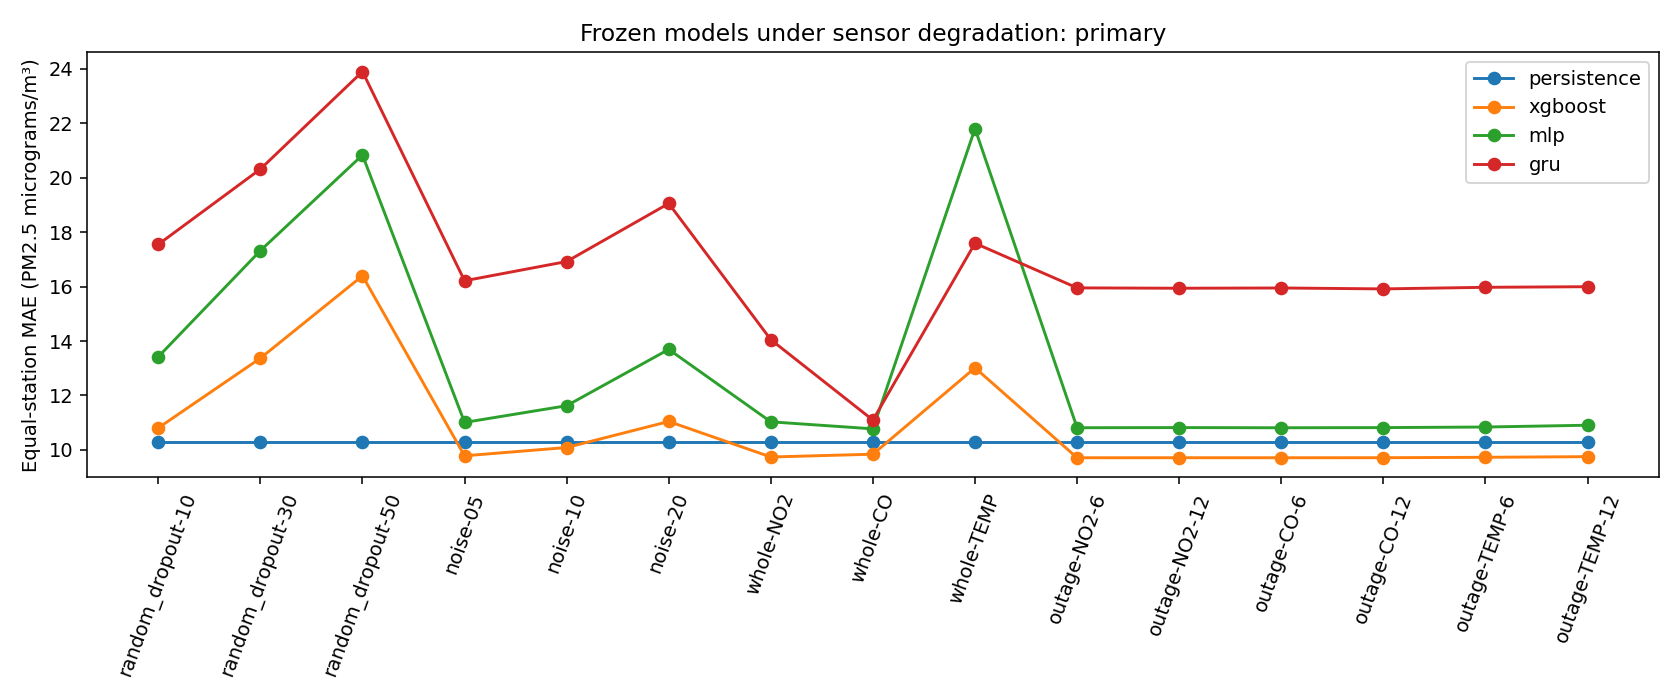

Paired intervals and selection regret are in each dashboard report's scopes.


In [15]:
import json
import pandas as pd
from airsense_r.artifacts import RunStore
from IPython.display import Image
output = ROOT / ".tmp/checkpoint-checkouts" / RUN_ID / "results" / RUN_ID
manifest = json.loads((output / "manifest.json").read_text())
store = RunStore(output, manifest["provenance"])
display(store.load_json("preflight-complete.json"))
if STAGE == "evaluate":
    display(store.load_json("complete.json"))
    payload = store.load_json("dashboard-p6.json")
    rows = []
    for report in payload["reports"]:
        for scope, summary in report["scopes"].items():
            for metric in summary["metrics"]:
                rows.append({"policy": report["policy"], "condition": report["condition"]["id"],
                             "scope": scope, **metric})
    display(pd.DataFrame(rows))
    display(Image(filename=str(output / "figure-p6-primary.png")))
    print("Paired intervals and selection regret are in each dashboard report's scopes.")


## Interpretation and retention
Synthetic stresses do not establish physical sensor-fault realism or embedded deployment. Whole-channel loss is deterministic; do not count its one realization as five replications. The no-forward-fill arm changes inference imputation only, with the same trained models and its own matched clean comparator. Sparse outage-affected uncertainty may be explicitly unavailable; never substitute independent-row intervals. Full-period headline intervals are mandatory. Preserve model snapshots, P6 Drive arrays and result branches. Save the executed notebook separately and request review before declaring P6 complete.